# 딥러닝 1일차 — 퍼셉트론 · 논리 게이트 · XOR 문제 · 다층 퍼셉트론(MLP)

메모 `딥러닝_1일.txt` 의 딥러닝 부분을 교재에 맞춰 **코드로 직접 확인할 수 있게 정리 · 개선한 노트**입니다.
(교재 `딥러닝` 교재8 p.1~20 — 19. 딥러닝 개요 · 퍼셉트론 · 논리 게이트 · 단층 퍼셉트론의 한계와 MLP)

- 메모 · 교재에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.
- 오전에 한 고객 이탈 예측의 순열 특성 중요도는 [`churn_permutation_importance.ipynb`](./churn_permutation_importance.ipynb) 에 있습니다.

> 필요한 패키지 : `numpy`, `pandas`, `matplotlib`, `scikit-learn` (TensorFlow · PyTorch 없이 퍼셉트론을 직접 구현)

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 딥러닝 개요 (교재 p.3~7)

**딥러닝** : 인간의 뇌 신경망 구조를 모방한 **인공신경망(Artificial Neural Network)** 을 기반으로, 대량의 데이터에서 **스스로 특징을 학습**하는 머신러닝의 한 분야.

```
인공지능 (규칙 기반 시스템 · 전문가 시스템 …)
 └─ 머신러닝 (결정 트리 · 선형 회귀 · 퍼셉트론 …)
     └─ 딥러닝 (깊은 인공신경망 : CNN · RNN · 심층 강화학습 …)
```

| 비교 항목 | 머신러닝 | 딥러닝 |
|---|---|---|
| 특징 추출 | 사람이 직접 정의 (**특성 공학** — Day 020 의 파생 변수 · 인코딩) | 모델이 데이터로부터 **스스로** 학습 |
| 데이터 의존도 | **적은 데이터로도** 유의미한 성능 | 데이터가 **많을수록** 성능이 커짐 |
| 학습 시간 | 수 초 ~ 수 시간 | 수 일 ~ 수 주 |
| 연산 자원 | 일반 CPU | GPU · TPU 같은 병렬 연산 장치 |
| 잘 맞는 데이터 | **표(정형) 데이터** — 붓꽃, 고객 이탈 | **이미지 · 소리 · 문장(비정형)** |
| 대표 알고리즘 | 결정 트리, 로지스틱 회귀 … | CNN, RNN, LSTM, Transformer, BERT … |

| 알고리즘 | 핵심 아이디어 | 용도 |
|---|---|---|
| **CNN** (합성곱 신경망) | 이미지의 **공간 구조**를 유지하며 필터로 특징 추출 | 컴퓨터 비전 — 이미지 분류 · 객체 탐지 · 세그멘테이션 |
| **RNN / LSTM** (순환 신경망) | **은닉층의 출력을 다시 입력**으로 순환시켜 순서 · 시간 흐름을 기억 | 시계열 예측, 초기 자연어 처리(감성 분석) |
| **Transformer / BERT** | 문장 안 단어들의 관계를 **동시에** 보는 Self-Attention | 거대 언어 모델(LLM), 문장 유사도 |

| 프레임워크 | 주도 | 특징 |
|---|---|---|
| TensorFlow & Keras | 구글 | 직관적인 코드 — 입문 · 프로토타이핑 |
| PyTorch | 메타 | 연구 · 산업의 사실상 표준 |

> **📝 고친 부분** (`딥러닝_1일.txt`)
> - "데이터 의존도 : 머신러닝은 데이터가 **적어야** 하지만" → 머신러닝은 데이터가 **적어도** 괜찮다(적을수록 좋다는 뜻이 아니다). 딥러닝은 데이터가 많아야 한다.
> - "신경망 : 스스로 **정답과 문제를 구분**한다" → 정답(레이블)은 여전히 사람이 준다(지도 학습). 신경망이 스스로 하는 것은 **특징(feature)을 뽑는 일** — 머신러닝에서 사람이 하던 특성 공학을 대신한다.
> - "딥러닝(**표 형식 데이터**)" → 딥러닝도 표 데이터에 쓸 수 있지만, 표 데이터는 보통 랜덤 포레스트 · XGBoost 같은 **트리 앙상블**이 더 강하다. 딥러닝이 압도적인 곳은 이미지 · 문장 같은 비정형 데이터.
> - "은닉**측**의 출력을 다시 입력 구조" → 은닉**층**의 출력을 다시 입력으로 **순환시키는** 구조, 오타 `게그맨테이션` → 세그멘테이션, `Teansformer` → Transformer

## 2. 퍼셉트론(perceptron) — 인공 뉴런 하나 (교재 p.8~11)

**perception(지각) + neuron(신경세포) → perceptron** : 다수의 입력 신호를 받아 **하나의 신호(0 또는 1)** 를 출력하는 인공 뉴런.

| 용어 | 뜻 |
|---|---|
| 입력 $x_1, x_2, …$ | 들어오는 신호 (특성) |
| **가중치** $w_1, w_2, …$ | 입력 신호에 **곱하는 계수** — 그 입력이 얼마나 중요한지 |
| **편향** $b$ | 뉴런이 얼마나 쉽게 1 을 내는지 (임계값 θ 를 왼쪽으로 옮긴 것, $b = -θ$) |
| 가중합 $z$ | $z = w_1x_1 + w_2x_2 + … + w_nx_n + b$ |
| 출력 $y$ | $z \ge 0$ 이면 **1**(신호를 보냄), $z < 0$ 이면 **0** — **계단 함수** |

$$y = \begin{cases} 0 & (w_1x_1 + w_2x_2 < θ) \\ 1 & (w_1x_1 + w_2x_2 \ge θ) \end{cases} \;\Rightarrow\; y = \begin{cases} 0 & (b + w_1x_1 + w_2x_2 < 0) \\ 1 & (b + w_1x_1 + w_2x_2 \ge 0) \end{cases}$$

$z = w_1x_1 + w_2x_2 + b = 0$ 은 **직선의 방정식** → 퍼셉트론은 평면을 직선 하나로 나누는 **선형 이진 분류기**(결정 경계). 로지스틱 회귀(Day 022)와 같은 모양에서 출력만 **확률(시그모이드) 대신 0/1(계단)** 이다.

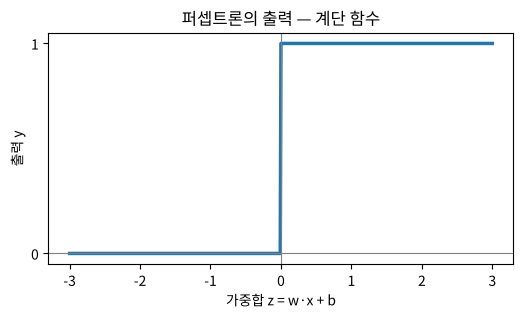

In [2]:
import numpy as np
import pandas as pd

# 계단 함수(step function) : z >= 0 이면 1, 아니면 0
def step(z):
    return (np.asarray(z) >= 0).astype(int)

z = np.linspace(-3, 3, 601)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(z, step(z), lw=2.5)
ax.axvline(0, color='gray', lw=0.8); ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('가중합 z = w·x + b'); ax.set_ylabel('출력 y')
ax.set_yticks([0, 1]); ax.set_title('퍼셉트론의 출력 — 계단 함수')
plt.show()

In [3]:
# 퍼셉트론 하나 : 입력 x(여러 개 가능) · 가중치 w · 편향 b → 0 또는 1
def perceptron(x, w, b):
    z = np.dot(x, w) + b        # 가중합 (행렬이면 행마다 한꺼번에 계산)
    return step(z)

# 입력 조합 4가지 (x1, x2)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
print(X)

[[0 0]
 [0 1]
 [1 0]
 [1 1]]


> **📝 고친 부분** (메모)
> - "인공뉴런 : 다수의 입력을 전부 받아 **변수와 출력 동시**한다" → 다수의 입력을 받아 **하나의 출력**(0 / 1)을 낸다.
> - "가중치 : **임계값 넘어야**, 뉴런의 출력 신호를 낼지 말지 결정하기 위해 신호" → 가중치는 **입력에 곱하는 계수**이고, 임계값(또는 편향)과 비교하는 것은 **가중합**이다.
> - "가중치 합 : **가중치 전부 곱해야** 임계값보다 커야 1" → 가중치끼리 곱하는 게 아니라 **입력 × 가중치를 모두 더한 값**(가중합)이 임계값 이상이면 1.
> - "0 : wx + wx < 0 / 1 : wx + wx >= 0" → **편향 b** 가 빠졌다. $w_1x_1 + w_2x_2 + b$ 와 0 을 비교한다(b 가 없으면 원점을 지나는 직선만 그을 수 있다).

## 3. 논리 게이트를 퍼셉트론으로 (교재 p.12~15)

논리 게이트 = 컴퓨터(CPU)를 이루는 가장 작은 **스위치**. 입력이 **조건(규칙)** 을 만족할 때만 신호(1)를 통과시킨다 — 수문(gate)처럼.

| 게이트 | 규칙 |
|---|---|
| **AND** (논리곱) | 입력이 **모두 1** 일 때만 1 |
| **OR** (논리합) | 입력 중 **하나라도 1** 이면 1 |
| **NAND** (부정 논리곱) | AND 를 뒤집은 것 — **모두 1 일 때만 0** |
| **XOR** (배타적 논리합) | 두 입력이 **서로 다를 때만** 1 |

**가중치와 편향만 바꾸면** 같은 퍼셉트론이 다른 게이트가 된다.

In [4]:
# 교재 p.15 의 가중치 · 편향
gates = {
    'AND':  (np.array([0.5, 0.5]), -0.7),     # 0.5·x1 + 0.5·x2 - 0.7 >= 0  → 둘 다 1 일 때만 (1.0 - 0.7 = 0.3)
    'OR':   (np.array([0.5, 0.5]), -0.2),     # 하나만 1 이어도 0.5 - 0.2 = 0.3 >= 0
    'NAND': (np.array([-0.5, -0.5]), 0.7),    # AND 의 부호를 전부 뒤집음
}

truth = pd.DataFrame(X, columns=['x1', 'x2'])
for name, (w, b) in gates.items():
    truth[f'z ({name})'] = (X @ w + b).round(2)       # 가중합
    truth[name] = perceptron(X, w, b)                  # 출력
truth['XOR (정답)'] = [0, 1, 1, 0]
truth

,x1,x2,z (AND),AND,z (OR),OR,z (NAND),NAND,XOR (정답)
0,0,0,-0.7,0,-0.2,0,0.7,1,0
1,0,1,-0.2,0,0.3,1,0.2,1,1
2,1,0,-0.2,0,0.3,1,0.2,1,1
3,1,1,0.3,1,0.8,1,-0.3,0,0


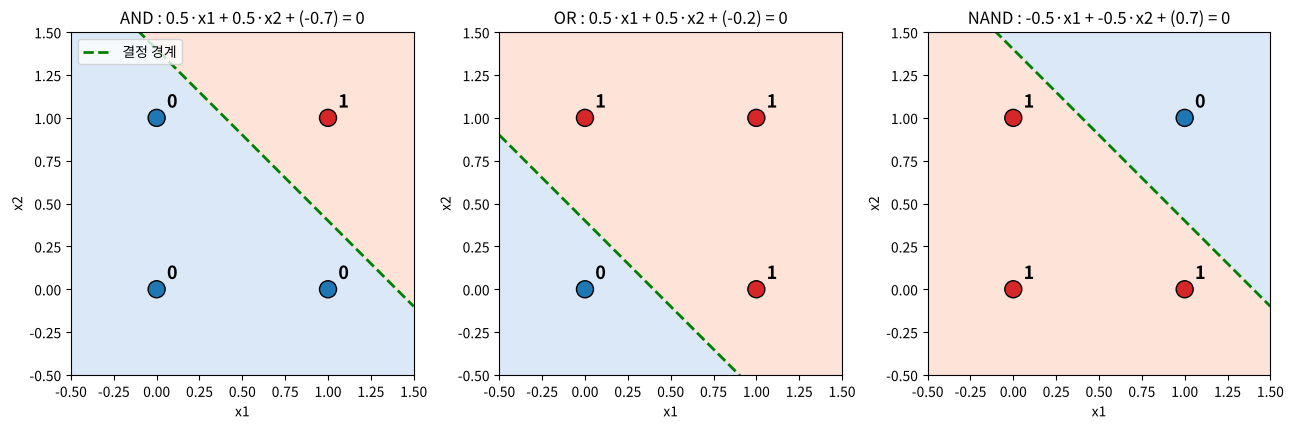

In [5]:
# 결정 경계 : w1·x1 + w2·x2 + b = 0  →  x2 = -(w1·x1 + b) / w2
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
xs = np.linspace(-0.5, 1.5, 50)
for ax, (name, (w, b)) in zip(axes, gates.items()):
    out = perceptron(X, w, b)
    gx, gy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
    region = perceptron(np.c_[gx.ravel(), gy.ravel()], w, b).reshape(gx.shape)
    ax.contourf(gx, gy, region, levels=[-0.5, 0.5, 1.5], colors=['#dbe8f8', '#fde3d8'])
    ax.plot(xs, -(w[0] * xs + b) / w[1], 'g--', lw=2, label='결정 경계')
    ax.scatter(X[:, 0], X[:, 1], c=['tab:blue' if o == 0 else 'tab:red' for o in out], s=150, edgecolor='k', zorder=3)
    for (a, c), o in zip(X, out):
        ax.text(a + 0.06, c + 0.06, str(o), fontsize=13, weight='bold')
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5); ax.set_aspect('equal')
    ax.set_title(f'{name} : {w[0]}·x1 + {w[1]}·x2 + ({b}) = 0')
    ax.set_xlabel('x1'); ax.set_ylabel('x2')
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

![편향 애니메이션](./images/anim_01_bias_gate.gif)

🎬 가중치를 0.5, 0.5 로 고정하고 **편향 b 만** +0.3 → −1.3 으로 내렸다. 결정 경계(초록 점선)가 오른쪽 위로 밀려나면서 1 을 내는 영역(주황)이 줄어들고, 출력이 **항상 1 → OR(b = −0.2) → AND(b = −0.7) → 항상 0** 으로 바뀐다. 편향은 "뉴런이 얼마나 쉽게 켜지는가" 다.

> **📝 고친 부분** (메모 · 교재)
> - "개념 : **등록된 데이터만** 전기가 흐른다" → 입력이 게이트의 **조건(규칙)을 만족할 때만** 1(전기가 흐름)을 낸다.
> - "논리 연산자 : AND, OR, (NAND, XOR) "NOT" (기울기) 가중치" · "**부정** 연산자 : NAND, XOR" → NAND 는 AND 의 **부정**(NOT AND)이 맞지만, **XOR 은 부정 연산자가 아니라 배타적 논리합**(서로 다를 때 1)이다. NOT 은 입력 1개짜리 게이트(가중치 −1, 편향 0.5 인 퍼셉트론).
> - 오타 `베타적` → 배타적
> - 메모의 계산 "0.5\*1 + 0.5\***2** − 0.7" → 논리 게이트의 입력은 **0 또는 1** 뿐이다. 둘 다 1 이면 0.5·1 + 0.5·1 − 0.7 = **0.3 ≥ 0 → 1**, 하나만 1 이면 0.5 − 0.7 = −0.2 < 0 → 0. 메모의 "b = 0.7" 도 부호가 반대 — AND 의 편향은 **−0.7**.

## 4. 가중치는 "학습"으로 정해진다 — 퍼셉트론 학습 규칙

위에서는 사람이 가중치(0.5, 0.5, −0.7)를 정해 줬다. 딥러닝의 핵심은 **데이터를 보고 가중치를 스스로 고치는 것**(메모 : "딥러닝 : 가중치가 학습으로 바뀐다").
로젠블랫(1958)의 퍼셉트론 학습 규칙 — 틀렸을 때만 오차 방향으로 조금씩 고친다.

$$w \leftarrow w + η\,(y - \hat{y})\,x, \qquad b \leftarrow b + η\,(y - \hat{y})$$

- $y - \hat y = +1$ (1 을 0 으로 틀림) → 가중합을 **키우는** 방향, $-1$ (0 을 1 로 틀림) → **줄이는** 방향
- $η$ = 학습률(learning rate) : 한 번에 고치는 크기

In [6]:
def train_perceptron(X, y, lr=0.25, epochs=20):
    w = np.zeros(X.shape[1])     # 가중치 0 에서 시작
    b = 0.0
    for epoch in range(1, epochs + 1):
        errors = 0
        for xi, yi in zip(X, y):                 # 데이터 하나씩
            y_hat = int(np.dot(xi, w) + b >= 0)  # 현재 퍼셉트론의 예측
            update = lr * (yi - y_hat)           # 맞으면 0 → 아무것도 안 바꿈
            if update != 0:
                w = w + update * xi
                b = b + update
                errors += 1
        print(f"epoch {epoch:>2} : 틀린 개수 {errors}  w = {w}, b = {b:+.2f}")
        if errors == 0:                          # 4개를 모두 맞히면 종료
            break
    return w, b

y_and = np.array([0, 0, 0, 1])
w_and, b_and = train_perceptron(X, y_and)
print("학습한 AND :", perceptron(X, w_and, b_and), " 정답 :", y_and)

epoch  1 : 틀린 개수 2  w = [0.25 0.25], b = +0.00
epoch  2 : 틀린 개수 3  w = [0.5  0.25], b = -0.25
epoch  3 : 틀린 개수 3  w = [0.5  0.25], b = -0.50
epoch  4 : 틀린 개수 2  w = [0.5 0.5], b = -0.50
epoch  5 : 틀린 개수 1  w = [0.5  0.25], b = -0.75
epoch  6 : 틀린 개수 0  w = [0.5  0.25], b = -0.75
학습한 AND : [0 0 0 1]  정답 : [0 0 0 1]


In [7]:
# OR 과 NAND 도 같은 함수로 학습된다
for name, y in [('OR', np.array([0, 1, 1, 1])), ('NAND', np.array([1, 1, 1, 0]))]:
    print(f"[{name}]")
    w, b = train_perceptron(X, y)
    print("예측 :", perceptron(X, w, b), " 정답 :", y, "\n")

[OR]
epoch  1 : 틀린 개수 2  w = [0.   0.25], b = +0.00
epoch  2 : 틀린 개수 2  w = [0.25 0.25], b = +0.00
epoch  3 : 틀린 개수 1  w = [0.25 0.25], b = -0.25
epoch  4 : 틀린 개수 0  w = [0.25 0.25], b = -0.25
예측 : [0 1 1 1]  정답 : [0 1 1 1] 

[NAND]
epoch  1 : 틀린 개수 1  w = [-0.25 -0.25], b = -0.25
epoch  2 : 틀린 개수 3  w = [-0.5  -0.25], b = +0.00
epoch  3 : 틀린 개수 3  w = [-0.5  -0.25], b = +0.25
epoch  4 : 틀린 개수 2  w = [-0.5 -0.5], b = +0.25
epoch  5 : 틀린 개수 1  w = [-0.5  -0.25], b = +0.50
epoch  6 : 틀린 개수 0  w = [-0.5  -0.25], b = +0.50
예측 : [1 1 1 0]  정답 : [1 1 1 0] 



![퍼셉트론 학습 애니메이션](./images/anim_02_perceptron_learning.gif)

🎬 가중치 0 에서 시작해 AND 데이터를 한 개씩 보면서 틀릴 때마다 결정 경계를 옮긴다. **6 epoch** 만에 4개를 모두 맞힌다. (학습으로 찾은 경계는 점에 딱 붙어 있다 — $z = 0$ 도 1 로 치기 때문. 교재의 0.5, 0.5, −0.7 은 여유(margin)를 둔 경계다.)

## 5. XOR — 직선 하나로는 안 된다 (교재 p.16~17)

| x1 | x2 | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | **1** |
| 1 | 0 | **1** |
| 1 | 1 | 0 |

0 은 (0,0) · (1,1), 1 은 (0,1) · (1,0) — **대각선으로 엇갈려** 있어서 **직선 하나로는 나눌 수 없다(선형 분리 불가능)**.

In [8]:
y_xor = np.array([0, 1, 1, 0])

# 1) 학습 규칙으로 시도 → 영원히 0 개로 줄지 않는다
w_xor, b_xor = train_perceptron(X, y_xor, epochs=10)
print("예측 :", perceptron(X, w_xor, b_xor), " 정답 :", y_xor)

epoch  1 : 틀린 개수 3  w = [-0.25  0.  ], b = -0.25
epoch  2 : 틀린 개수 3  w = [-0.25  0.  ], b = +0.00
epoch  3 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
epoch  4 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
epoch  5 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
epoch  6 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
epoch  7 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
epoch  8 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
epoch  9 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
epoch 10 : 틀린 개수 4  w = [-0.25  0.  ], b = +0.00
예측 : [1 1 0 0]  정답 : [0 1 1 0]


In [9]:
# 2) 가중치 · 편향을 -1 ~ 1 (0.1 간격) 으로 전부 시도해 보면?
grid = np.round(np.arange(-1, 1.01, 0.1), 2)
best = 0
for w1 in grid:
    for w2 in grid:
        for b in grid:
            acc = (perceptron(X, np.array([w1, w2]), b) == y_xor).mean()
            best = max(best, acc)
print(f"{len(grid) ** 3:,}가지 직선 중 최고 정확도 : {best}  → 4개 중 3개까지만 맞힌다")

9,261가지 직선 중 최고 정확도 : 0.75  → 4개 중 3개까지만 맞힌다


![XOR 실패 애니메이션](./images/anim_03_xor_fail.gif)

🎬 XOR 데이터에 같은 학습 규칙을 돌리면 하나를 맞히려고 경계를 옮기면 다른 하나가 틀려서, 경계가 **같은 자리를 맴돌 뿐 틀린 개수가 0 이 되지 않는다**(3 epoch 부터는 매 epoch 4개 모두 한 번씩 틀린다). 9,261가지 직선을 다 그어 봐도 최고 **4개 중 3개**.

**왜 중요한가 — 첫 번째 AI 겨울** : 1969년 민스키 · 페퍼트의 책 《Perceptrons》 가 "단층 퍼셉트론은 XOR 도 못 푼다"를 수학적으로 보였고, 다층 신경망을 **학습시킬 방법**도 당시엔 없었다. 연구 지원이 끊기며 약 20년간 침체 → 1986년 **오차역전파(backpropagation)** 로 다층 신경망을 학습시킬 수 있게 되면서 "Deep" 이 시작됐다.

## 6. 다층 퍼셉트론(MLP) — 층을 쌓으면 풀린다 (교재 p.18~20)

**입력층 → 은닉층 → 출력층**. 은닉층에 NAND 와 OR 를 **나란히** 두고, 그 결과를 AND 로 합친다.

$$\text{Input}(x_1, x_2) \rightarrow \begin{cases} \text{NAND} \rightarrow s_1 \\ \text{OR} \rightarrow s_2 \end{cases} \rightarrow \text{AND}(s_1, s_2) \rightarrow y$$

In [10]:
def XOR(x):
    s1 = perceptron(x, *gates['NAND'])          # 은닉층 노드 1 : NAND
    s2 = perceptron(x, *gates['OR'])            # 은닉층 노드 2 : OR
    hidden = np.column_stack([s1, s2])          # 은닉층의 출력 → 다음 층의 입력
    return perceptron(hidden, *gates['AND']), s1, s2   # 출력층 : AND

y_pred, s1, s2 = XOR(X)
table = pd.DataFrame({'입력 X1': X[:, 0], '입력 X2': X[:, 1],
                      '은닉층 H1 (NAND)': s1, '은닉층 H2 (OR)': s2,
                      '출력층 Y (AND)': y_pred, 'XOR 정답': y_xor})
table

,입력 X1,입력 X2,은닉층 H1 (NAND),은닉층 H2 (OR),출력층 Y (AND),XOR 정답
0,0,0,1,0,0,0
1,0,1,1,1,1,1
2,1,0,1,1,1,1
3,1,1,0,1,0,0


교재 p.20 의 진리표와 같다 — **퍼셉트론 3개(2층)** 로 XOR 이 풀렸다.

![MLP XOR 애니메이션](./images/anim_04_mlp_xor.gif)

🎬 왜 풀리는가 : 은닉층이 점들을 **새 좌표 (s1, s2)** 로 옮긴다. 원래 공간에서 엇갈려 있던 (0,0) · (1,1) 이 은닉층 공간에서는 (1,0) · (0,1) 로, (0,1) · (1,0) 은 둘 다 (1,1) 로 모인다 → 이제 **직선 하나(AND)** 로 나뉜다. 층을 쌓는다 = **문제를 풀기 쉬운 공간으로 데이터를 바꾸는 것**이고, 딥러닝이 "특징을 스스로 학습한다"는 말의 뜻이다.

> **📝 고친 부분** (메모 · 교재)
> - 메모 "은닉층 노드 1(h1) : NAND 연산 (**값이 같으면 1, 다르면 0**)" · 교재 p.18 "(**값이 같으면 0, 다르면 1**)" → 둘 다 NAND 가 아니다. 앞의 것은 XNOR, 뒤의 것은 XOR 의 설명이다. NAND 는 **두 입력이 모두 1 일 때만 0, 나머지는 1** — 교재 p.20 진리표의 H1 열(1, 1, 1, 0)이 맞다.
> - 메모 "단층 퍼셉트론의 한계 … (w1x1 + w2x2 + b = 0) b=0.7" → 단층 퍼셉트론의 한계는 이 식이 **직선**이라는 것. b 값은 게이트마다 다르다(AND −0.7, OR −0.2, NAND +0.7).

## 7. 미리 보기 — scikit-learn 으로 같은 실험

sklearn 의 `Perceptron`(단층)과 `MLPClassifier`(다층 퍼셉트론)로 XOR 을 학습시켜 본다. MLP 는 사람이 NAND · OR 를 정해 주지 않아도 **오차역전파로 은닉층 가중치를 스스로 찾는다**.

In [11]:
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

for name, y in [('AND', y_and), ('XOR', y_xor)]:
    p = Perceptron(max_iter=1000, random_state=0).fit(X, y)
    print(f"단층 Perceptron  {name} : 예측 {p.predict(X)}  정확도 {p.score(X, y):.2f}")

mlp = MLPClassifier(hidden_layer_sizes=(4,),   # 은닉층 1개, 뉴런 4개
                    activation='tanh',         # 계단 함수 대신 미분 가능한 함수 (역전파에 필요)
                    solver='lbfgs', max_iter=1000, random_state=0)
mlp.fit(X, y_xor)
print(f"MLPClassifier   XOR : 예측 {mlp.predict(X)}  정확도 {mlp.score(X, y_xor):.2f}")
print("출력이 1 일 확률 :", mlp.predict_proba(X)[:, 1].round(3))

단층 Perceptron  AND : 예측 [0 0 0 1]  정확도 1.00
단층 Perceptron  XOR : 예측 [0 0 0 0]  정확도 0.50
MLPClassifier   XOR : 예측 [0 1 1 0]  정확도 1.00
출력이 1 일 확률 : [0.    1.    0.999 0.001]


In [12]:
# 은닉 뉴런 2개면 이론상 충분하지만, 시작 가중치(random_state)에 따라 학습이 막히기도 한다
for rs in range(5):
    m = MLPClassifier(hidden_layer_sizes=(2,), activation='tanh', solver='lbfgs',
                      max_iter=1000, random_state=rs).fit(X, y_xor)
    print(f"random_state={rs} : 예측 {m.predict(X)}  {'성공' if m.score(X, y_xor) == 1 else '실패'}")

random_state=0 : 예측 [0 0 1 0]  실패
random_state=1 : 예측 [0 1 1 0]  성공
random_state=2 : 예측 [0 1 0 0]  실패
random_state=3 : 예측 [0 1 0 1]  실패
random_state=4 : 예측 [0 1 1 0]  성공


## 8. 정리

| | 단층 퍼셉트론 | 다층 퍼셉트론 (MLP) |
|---|---|---|
| 구조 | 입력층 → 출력층 | 입력층 → **은닉층** → 출력층 |
| 결정 경계 | **직선 하나** | 직선 여러 개를 조합한 **곡선 · 복잡한 경계** |
| 풀 수 있는 것 | AND · OR · NAND (선형 분리 가능) | XOR 같은 선형 분리 **불가능** 문제 |
| 학습 | 퍼셉트론 학습 규칙 | **오차역전파** (출력의 오차를 뒤로 보내며 모든 층의 가중치 수정) |

- 퍼셉트론 = **가중합 + 편향 → 계단 함수**. 가중치 · 편향만 바꾸면 다른 게이트가 된다.
- 층을 쌓으면 은닉층이 데이터를 **새로운 공간으로 옮겨** 직선으로 나눌 수 있게 만든다 → 딥러닝의 출발점.
- 다음 시간 : 계단 함수 대신 시그모이드 · ReLU 같은 **활성화 함수**, 오차역전파 (교재 p.21~).